In [4]:
import pandas as pd 
df = pd.read_csv(r'C:\Users\ibrahim khan\Documents\smart_Energy_meter\Electric_power_dataset.csv') 
df

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964
...,...,...,...,...,...,...,...,...,...
52411,12/30/2017 23:10,7.010,72.4,0.080,0.040,0.096,31160.45627,26857.31820,14780.31212
52412,12/30/2017 23:20,6.947,72.6,0.082,0.051,0.093,30430.41825,26124.57809,14428.81152
52413,12/30/2017 23:30,6.900,72.8,0.086,0.084,0.074,29590.87452,25277.69254,13806.48259
52414,12/30/2017 23:40,6.758,73.0,0.080,0.066,0.089,28958.17490,24692.23688,13512.60504


In [15]:
 df.shape

(52416, 9)

In [17]:
df.isnull().sum()

Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

In [19]:
df.describe()

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


In [21]:
df['Datetime']=pd.to_datetime(df['Datetime'])
df['year']=df['Datetime'].dt.year
df['month']=df['Datetime'].dt.month 
df['day']=df['Datetime'].dt.day
df['hour']=df['Datetime'].dt.hour   
df['minute']=df['Datetime'].dt.minute 

In [23]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,year,month,day,hour,minute
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,1,0,0
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,1,0,10
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,1,0,20
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,1,0,30
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,1,0,40


<Axes: >

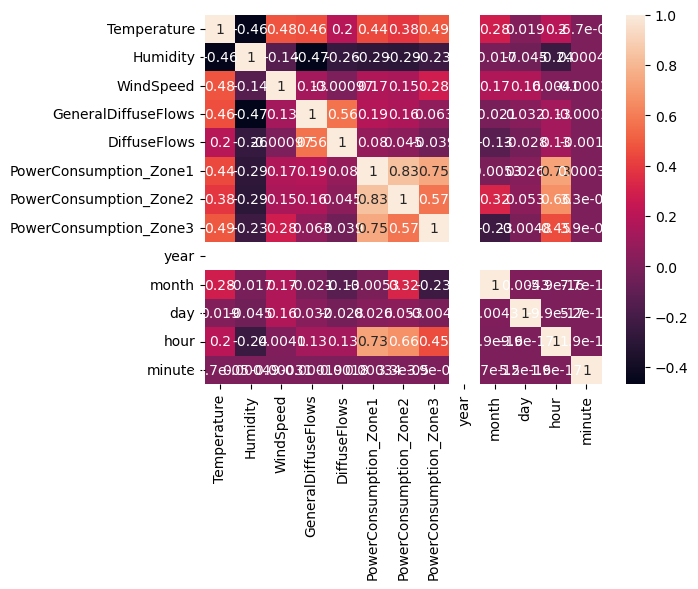

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True)

In [17]:
print(df.columns.tolist())

['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3', 'year', 'month', 'Day', 'Hour', 'Minute']


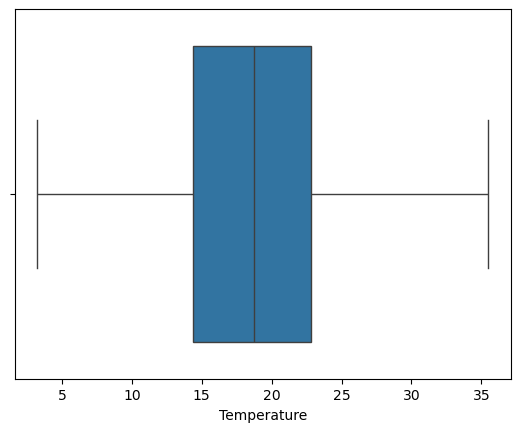

In [33]:
sns.boxplot(x=df['Temperature'])
plt.show()

In [35]:
 # Handle outliers
Q1 = df['Temperature'].quantile(0.25)
Q3 = df['Temperature'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['Temperature'] >= Q1 - 1.5*IQR) &
        (df['Temperature'] <= Q3 + 1.5*IQR)]

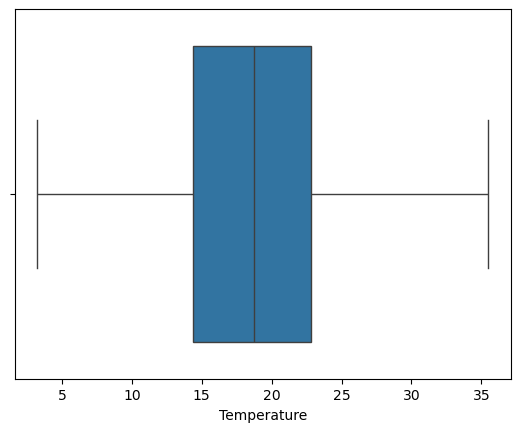

In [37]:
sns.boxplot(x=df['Temperature'])
plt.show()

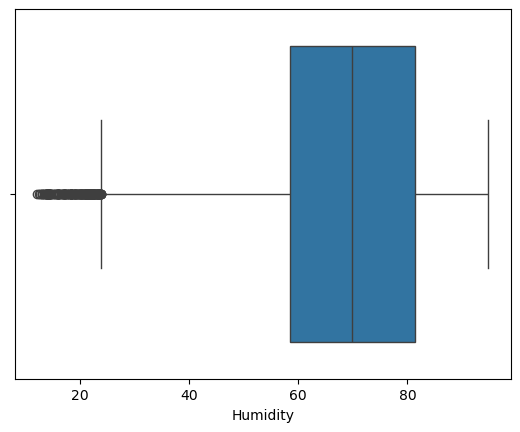

In [39]:
sns.boxplot(x=df['Humidity'])
plt.show() 

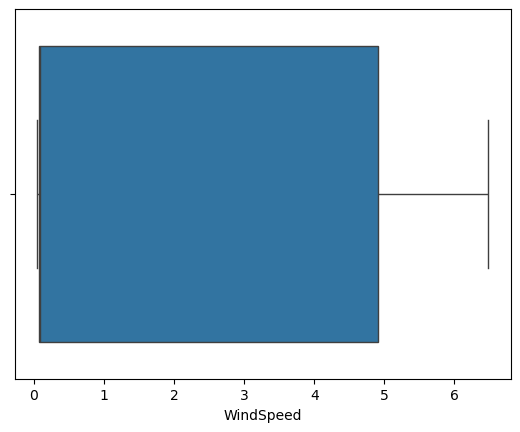

In [41]:
sns.boxplot(x=df['WindSpeed'])

plt.show()

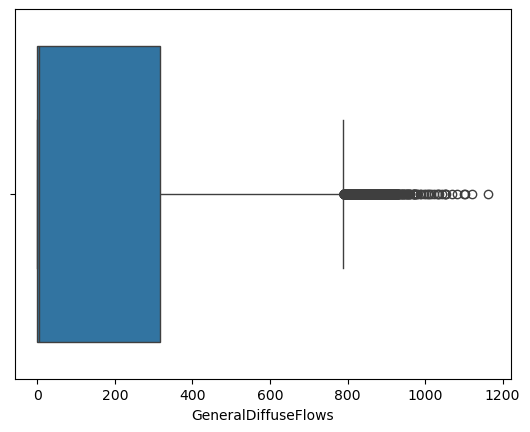

In [43]:
sns.boxplot(x=df['GeneralDiffuseFlows'])

plt.show()

In [45]:
Q1 = df['GeneralDiffuseFlows'].quantile(0.25)
Q3 = df['GeneralDiffuseFlows'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['GeneralDiffuseFlows'] < lower) |
              (df['GeneralDiffuseFlows'] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 2410


In [60]:
import numpy as np 
df['GeneralDiffuseFlows'] = np.log1p(df['GeneralDiffuseFlows'])

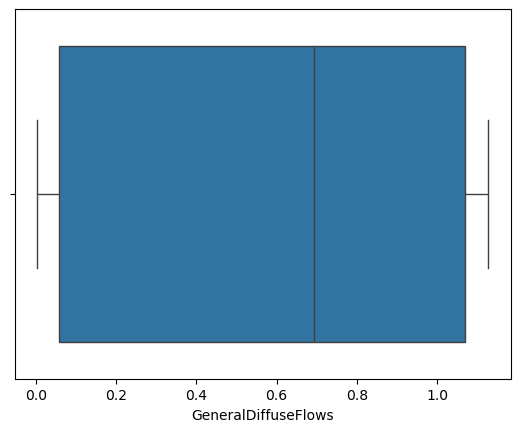

In [61]:
sns.boxplot(x=df['GeneralDiffuseFlows'])

plt.show()

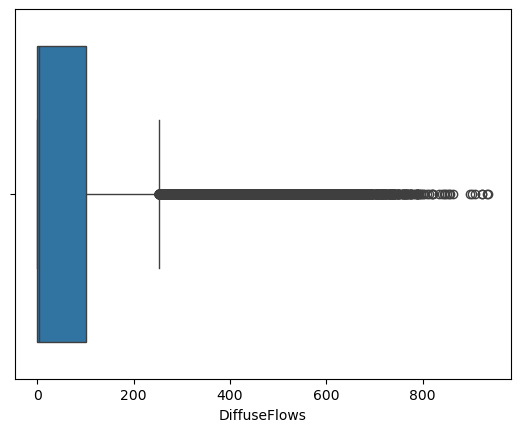

In [50]:
sns.boxplot(x=df['DiffuseFlows'])

plt.show()

In [52]:
Q1 = df['DiffuseFlows'].quantile(0.25)
Q3 = df['DiffuseFlows'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['DiffuseFlows'] < lower) |
              (df['DiffuseFlows'] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 4567


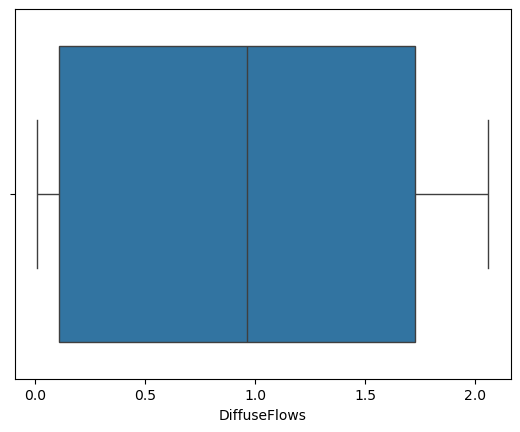

In [54]:
import numpy as np

df['DiffuseFlows'] = np.log1p(df['DiffuseFlows'])
sns.boxplot(x=df['DiffuseFlows'])

plt.show()

In [56]:
Q1 = df['DiffuseFlows'].quantile(0.25)
Q3 = df['DiffuseFlows'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['DiffuseFlows'] < lower) |
              (df['DiffuseFlows'] > upper)]

print("Number of outliers:", len(outliers))


Number of outliers: 0


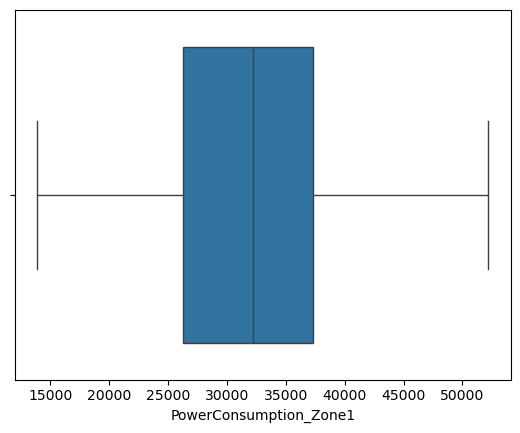

In [58]:
sns.boxplot(x=df['PowerConsumption_Zone1'])

plt.show()

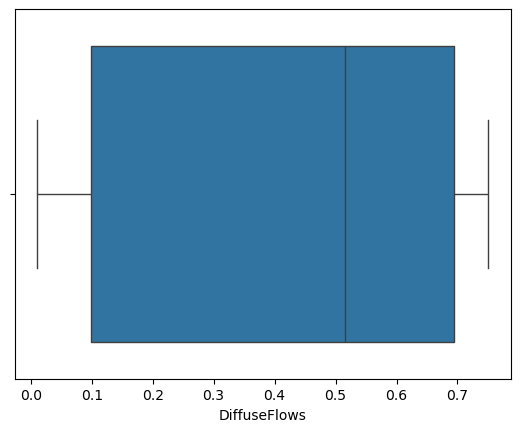

In [62]:
df['DiffuseFlows'] = np.log1p(df['DiffuseFlows'])
sns.boxplot(x=df['DiffuseFlows'])

plt.show()

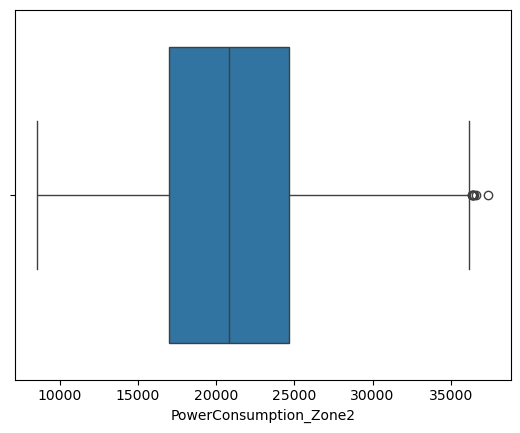

In [65]:
sns.boxplot(x=df['PowerConsumption_Zone2'])
plt.show()

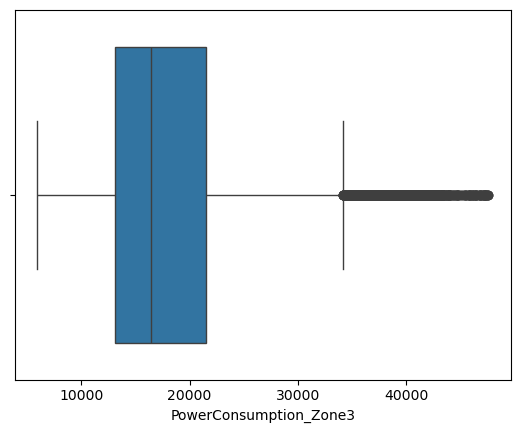

In [71]:
sns.boxplot(x=df['PowerConsumption_Zone3'])
plt.show()

In [8]:
# Input features
import pandas as pd 
df = pd.read_csv(r'C:\Users\ibrahim khan\Documents\smart_Energy_meter\Electric_power_dataset.csv')


In [10]:
# Input features
X = df.drop(
    ['PowerConsumption_Zone1',
     'PowerConsumption_Zone2',
     'PowerConsumption_Zone3'],
    axis=1
)

# Target values
Y = df[
    ['PowerConsumption_Zone1',
     'PowerConsumption_Zone2',
     'PowerConsumption_Zone3']
]

print("Input shape:", X.shape)
print("Target shape:", Y.shape)

Input shape: (52416, 6)
Target shape: (52416, 3)


In [23]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split( X, Y, test_size=0.2, random_state=42)

print("Training input shape:", x_train.shape)
print("Testing input shape:", x_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (41932, 10)
Testing input shape: (10484, 10)
Training target shape: (41932, 3)
Testing target shape: (10484, 3)


In [25]:
df.head()

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,year,month,Day,Hour,Minute
0,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,1,0,0
1,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,1,0,10
2,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,1,0,20
3,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,1,0,30
4,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,1,0,40


In [27]:
df.info(),

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature             52416 non-null  float64
 1   Humidity                52416 non-null  float64
 2   WindSpeed               52416 non-null  float64
 3   GeneralDiffuseFlows     52416 non-null  float64
 4   DiffuseFlows            52416 non-null  float64
 5   PowerConsumption_Zone1  52416 non-null  float64
 6   PowerConsumption_Zone2  52416 non-null  float64
 7   PowerConsumption_Zone3  52416 non-null  float64
 8   year                    52416 non-null  int32  
 9   month                   52416 non-null  int32  
 10  Day                     52416 non-null  int32  
 11  Hour                    52416 non-null  int32  
 12  Minute                  52416 non-null  int32  
dtypes: float64(8), int32(5)
memory usage: 4.2 MB


(None,)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#  Separating input features and target values
X = df.drop(
    columns=[
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
)

Y = df[
    [
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
]

#  Spliting the dataset
x_train, x_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

print("Non-numeric columns:", 
      x_train.select_dtypes(exclude='number').columns.tolist())

# Step 4: Scale the input features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Scaling completed successfully!")
print("Training shape:", x_train_scaled.shape)
print("Testing shape:", x_test_scaled.shape)

Non-numeric columns: []
Scaling completed successfully!
Training shape: (41932, 10)
Testing shape: (10484, 10)


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Create the model
model_lr = LinearRegression()

# 2. Train the model
model_lr.fit(x_train_scaled, y_train)

# 3. Predict consumption for all three zones
y_pred_lr = model_lr.predict(x_test_scaled)

# 4. Evaluate the model
mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
-------------------------
MAE: 3103.007552663084
RMSE: 3937.084346387933
R2 Score: 0.6099410745415853


In [35]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the model
model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model_rf.fit(x_train, y_train)

# Make predictions
y_pred_rf = model_rf.predict(x_test)

# Evaluate performance
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("----------------------")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
----------------------
MAE: 415.3787552692365
RMSE: 664.0341509782169
R2 Score: 0.9882900313742322


In [37]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the model for three target zones
model_gb = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
)

# Train
model_gb.fit(x_train, y_train)

# Predict
y_pred_gb = model_gb.predict(x_test)

# Evaluate
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("--------------------------")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R2 Score:", r2_gb)

Gradient Boosting Results
--------------------------
MAE: 1373.0044894944378
RMSE: 1858.4098955982063
R2 Score: 0.9109273831465609


In [39]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

zone_names = [
    'Zone 1',
    'Zone 2',
    'Zone 3'
]

for i, zone in enumerate(zone_names):
    actual = y_test.iloc[:, i]
    predicted = y_pred_rf[:, i]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{zone}")
    print(f"MAE:  {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2:   {r2:.4f}")


Zone 1
MAE:  505.31
RMSE: 781.60
R2:   0.9879

Zone 2
MAE:  431.68
RMSE: 689.14
R2:   0.9824

Zone 3
MAE:  309.14
RMSE: 486.85
R2:   0.9946


In [41]:
import pandas as pd

# Example input for a new prediction
new_data = pd.DataFrame([{
    'Temperature': 25.0,
    'Humidity': 60.0,
    'WindSpeed': 2.0,
    'GeneralDiffuseFlows': 100.0,
    'DiffuseFlows': 30.0,
    'year': 2017,
    'month': 6,
    'Day': 15,
    'Hour': 14,
    'Minute': 0
}])

# Predict consumption in all three zones
prediction = model_rf.predict(new_data)

print("Predicted electricity consumption:")
print("Zone 1:", round(prediction[0][0], 2))
print("Zone 2:", round(prediction[0][1], 2))
print("Zone 3:", round(prediction[0][2], 2))

Predicted electricity consumption:
Zone 1: 36344.58
Zone 2: 22903.37
Zone 3: 18988.5


In [45]:
import joblib

# Save the trained Random Forest model
joblib.dump(model_rf, "electricity_prediction_model.pkl")


['electricity_prediction_model.pkl']

In [44]:
import os
print(os.path.abspath("electricity_prediction_model.pkl"))

c:\Users\ibrahim khan\Documents\smart_Energy_meter\electricity_prediction_model.pkl
